In [1]:
# churn analysis project

In [2]:
import numpy as np  
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns  


In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
import sqlite3

In [5]:
conn = sqlite3.connect("customer_churn (1).db")

In [6]:
# sql query to Get all table names
sql_query = """
        SELECT name
        FROM sqlite_master
        WHERE type='table';
"""
# read sql query in pandas
tables = pd.read_sql(sql_query, conn)


In [7]:
# making 3 dfs :

for table in tables['name']:
    df_name = table.replace('db_', '')
    globals()['df_' + df_name] = pd.read_sql_query(
        f'SELECT * FROM "{table}"', conn
    )
# Close connection
conn.close()

In [8]:
# so we now have 3 tables:
df_customer
df_subscription
df_support


,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN
5,0017-IUDMW,2024-04-10 00:00:00,Y,25,None,NaN
6,0019-EFAEP,2024-09-27 00:00:00,Y,30,None,NaN
7,0022-TCJCI,2024-09-13 00:00:00,Y,10,None,NaN
8,0022-TCJCI,2024-09-14 00:00:00,N,90,None,received refund


In [9]:
# 1.EDA and 2. Data cleaning

df_customer.head()
# this is my first table 

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [10]:
df_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 1.4+ KB


In [11]:
# we will remove interests and pincode its incomplete and of no use.
df_customer.drop(columns=['interests','pincode'],inplace=True)

In [12]:
df_customer

,customerid,name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00


In [13]:
# dob should be in datetimeformat
df_customer['dob'] = pd.to_datetime(df_customer['dob'])

In [14]:
df_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   customerid  21 non-null     str           
 1   name        21 non-null     str           
 2   country     18 non-null     str           
 3   state       21 non-null     str           
 4   gender      21 non-null     str           
 5   dob         21 non-null     datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 1.1 KB


In [15]:
# what else we can do 
df_customer.head()

,customerid,name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05


In [16]:
# filing null values of country with state mapped
mapping = (
    df_customer.dropna(subset=['state', 'country'])
    .drop_duplicates(subset=['state'])
    .set_index('state')['country']
)

df_customer['country'] = df_customer['country'].fillna(
    df_customer['state'].map(mapping)
)

In [17]:
df_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   customerid  21 non-null     str           
 1   name        21 non-null     str           
 2   country     21 non-null     str           
 3   state       21 non-null     str           
 4   gender      21 non-null     str           
 5   dob         21 non-null     datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 1.1 KB


In [18]:
df_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,India,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,Nepal,Kathmandu
9,Nepal,Kathmandu


In [19]:
# gender  
df_customer['gender'].value_counts()
df_customer['gender']= df_customer['gender'].replace({'Women':'Female', 'Men':'Male'})

In [20]:
df_customer.rename(columns={'name':'customer_name'},inplace=True)

In [21]:
df_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05
5,0013-MHZWF,durga,India,Delhi,Female,1988-12-10
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14
8,0015-UOCOJ,maya,Nepal,Kathmandu,Female,1985-07-07
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29


In [22]:
df_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05
5,0013-MHZWF,durga,India,Delhi,Female,1988-12-10
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14
8,0015-UOCOJ,maya,Nepal,Kathmandu,Female,1985-07-07
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29


In [23]:
df_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     21 non-null     str           
 1   customer_name  21 non-null     str           
 2   country        21 non-null     str           
 3   state          21 non-null     str           
 4   gender         21 non-null     str           
 5   dob            21 non-null     datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 1.1 KB


<Axes: xlabel='gender', ylabel='count'>

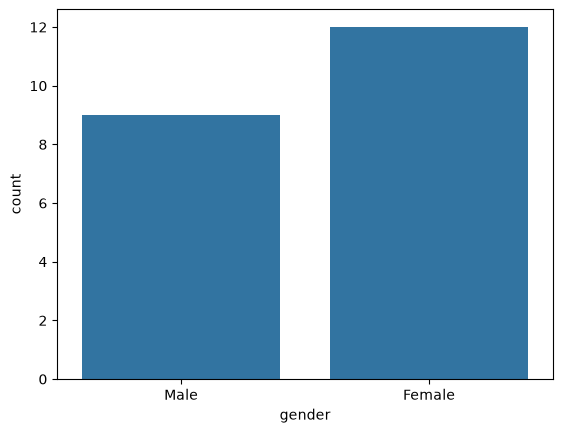

In [24]:
# just for testing : we can get data vis.
sns.countplot(x= df_customer['gender'])
# its fine now

In [25]:
 # subcription table
df_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [26]:
df_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [27]:
# all dates to correct formats 
date_cols = ['subscription_start_date', 'renewal_date', 'cancellation_date']

df_subscription[date_cols] = df_subscription[date_cols].apply(
    pd.to_datetime, errors='coerce'
)

In [28]:
df_subscription.head()
df_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


In [29]:
# exploring next table    
df_support.info()
df_support.head()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [30]:
df_support

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN
5,0017-IUDMW,2024-04-10 00:00:00,Y,25,None,NaN
6,0019-EFAEP,2024-09-27 00:00:00,Y,30,None,NaN
7,0022-TCJCI,2024-09-13 00:00:00,Y,10,None,NaN
8,0022-TCJCI,2024-09-14 00:00:00,N,90,None,received refund


In [31]:
df_support['complaint_date'] = pd.to_datetime(df_support['complaint_date'] )

In [32]:
df_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
 4   col_1           0 non-null      object        
 5   comment         4 non-null      str           
dtypes: datetime64[us](1), int64(1), object(1), str(3)
memory usage: 564.0+ bytes


In [33]:
df_support.drop(columns=['col_1','comment'],inplace=True)

In [34]:
df_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [35]:
df_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes


In [36]:
#  Feature Engineering & Data Analysis

In [37]:
df_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [38]:
df_subscription['churn_flag'] = (
    df_subscription['cancellation_date'].notna().astype(int)
)

In [39]:
df_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [40]:
# merge 3 dataframes ::
df = df_customer.merge(df_subscription, on='customerid', how='left')

df = df.merge(df_support, on='customerid', how='left')

In [41]:
df

,customerid,customer_name,country,state,gender,dob,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,complaint_date,escalations,csat_score
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0,NaT,NaN,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,2024-08-28,N,60.0
2,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,2024-08-28,Y,10.0
3,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0,NaT,NaN,NaN
4,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0,NaT,NaN,NaN
5,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1,2024-01-20,Y,20.0
6,0013-MHZWF,durga,India,Delhi,Female,1988-12-10,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,NaN,17.99,720,22,0,2025-03-18,N,90.0
7,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,79,1,2024-11-01,N,30.0
8,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,NaN,22.99,1840,5,0,NaT,NaN,NaN
9,0015-UOCOJ,maya,Nepal,Kathmandu,Female,1985-07-07,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,NaN,13.99,240,34,0,NaT,NaN,NaN


In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               23 non-null     str           
 1   customer_name            23 non-null     str           
 2   country                  23 non-null     str           
 3   state                    23 non-null     str           
 4   gender                   23 non-null     str           
 5   dob                      23 non-null     datetime64[us]
 6   subscription_start_date  23 non-null     datetime64[us]
 7   subscription_type        23 non-null     str           
 8   renewal_date             23 non-null     datetime64[us]
 9   plan_type                23 non-null     str           
 10  contract_type            23 non-null     str           
 11  cancellation_date        8 non-null      datetime64[us]
 12  cancellation_reason      8 non-null      str     

In [43]:
df.shape

(23, 20)

In [44]:
# but but but 21 after left join becomes 23, means it must have duplicates 
df_customer.shape


(21, 6)

In [45]:
print("Customer:", df_customer.shape)
print("Subscription:", df_subscription.shape)
print("Support:", df_support.shape)

Customer: (21, 6)
Subscription: (21, 12)
Support: (9, 4)


In [46]:
print("Duplicate customer IDs in subscription:",
      df_subscription['customerid'].duplicated().sum())

Duplicate customer IDs in subscription: 0


In [47]:
print("Duplicate customer IDs in support:",
      df_support['customerid'].duplicated().sum())

# mil gya issue

Duplicate customer IDs in support: 2


In [48]:
df_support[df_support['customerid'].duplicated(keep=False)].sort_values('customerid')

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [49]:
df_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [50]:
# col for complaints count
df_support['no_of_complaints'] = df_support.groupby('customerid')['customerid'].transform('count')

# 3. Latest complaint record 
df_support = df_support.sort_values('complaint_date').drop_duplicates(
    subset='customerid',
    keep='last'
)


In [51]:
df_support

,customerid,complaint_date,escalations,csat_score,no_of_complaints
2,0013-EXCHZ,2024-01-20,Y,20,1
5,0017-IUDMW,2024-04-10,Y,25,1
1,0003-MKNFE,2024-08-28,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2
6,0019-EFAEP,2024-09-27,Y,30,1
4,0013-SMEOE,2024-11-01,N,30,1
3,0013-MHZWF,2025-03-18,N,90,1


In [52]:
# Merge 3 dataframes again , now fine 
df = df_customer.merge(df_subscription, on='customerid', how='left')
df = df.merge(df_support, on='customerid', how='left')

In [53]:
df

,customerid,customer_name,country,state,gender,dob,subscription_start_date,subscription_type,renewal_date,plan_type,...,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,complaint_date,escalations,csat_score,no_of_complaints
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12,2021-03-15,Refferal,2025-03-15,Standard,...,NaT,NaN,13.99,627,12,0,NaT,NaN,NaN,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23,2020-08-01,Paid,2024-08-01,Premium,...,2024-09-10,Switched to competitor,12.99,1150,91,1,2024-08-28,Y,10.0,2.0
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15,2022-11-20,Organic,2025-11-20,Basic,...,NaT,NaN,6.99,210,34,0,NaT,NaN,NaN,NaN
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30,2019-05-10,Paid,2025-05-10,Premium,...,NaT,NaN,22.99,1725,8,0,NaT,NaN,NaN,NaN
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05,2023-01-05,Refferal,2024-01-05,Standard,...,2024-02-28,Too expensive,13.99,195,88,1,2024-01-20,Y,20.0,1.0
5,0013-MHZWF,durga,India,Delhi,Female,1988-12-10,2022-06-18,Paid,2025-06-18,Standard,...,NaT,NaN,17.99,720,22,0,2025-03-18,N,90.0,1.0
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21,2021-09-30,Refferal,2024-09-30,Basic,...,2024-11-15,Not enough content,8.99,230,79,1,2024-11-01,N,30.0,1.0
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14,2020-02-14,Organic,2025-02-14,Premium,...,NaT,NaN,22.99,1840,5,0,NaT,NaN,NaN,NaN
8,0015-UOCOJ,maya,Nepal,Kathmandu,Female,1985-07-07,2023-07-22,Organic,2024-07-22,Standard,...,NaT,NaN,13.99,240,34,0,NaT,NaN,NaN,NaN
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29,2022-04-03,Organic,2025-04-03,Basic,...,NaT,NaN,6.99,335,41,0,NaT,NaN,NaN,NaN


In [54]:
df.shape

(21, 21)

In [55]:
#Data Analysis

In [56]:
# export dataframe to csv file
df.to_csv('exported_churn_data.csv', index=False)

PermissionError: [Errno 13] Permission denied: 'exported_churn_data.csv'

In [57]:
# 1. Churn Rate
churn_rate = round(len(df[df['churn_flag'] == 1]) / len(df) * 100, 2)

print(f"Overall Churn Rate: {churn_rate}%")

Overall Churn Rate: 28.57%


In [58]:
# 2. Retention Rate
retention_rate = round(len(df[df['churn_flag'] == 0]) / len(df) * 100, 2)

print(f"Overall Retention Rate: {retention_rate}%")

Overall Retention Rate: 71.43%


In [59]:
# 3. Churn by Plan type
df.columns

Index(['customerid', 'customer_name', 'country', 'state', 'gender', 'dob',
       'subscription_start_date', 'subscription_type', 'renewal_date',
       'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'complaint_date', 'escalations', 'csat_score',
       'no_of_complaints'],
      dtype='str')

In [60]:
# 3. Churn Rate by Plan Type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean() * 100).round(2)

print("Churn Rate by Plan Type:")
print(churn_by_plan)

Churn Rate by Plan Type:
plan_type
Basic       60.00
Premium     14.29
Standard    22.22
Name: churn_flag, dtype: float64


In [61]:
# 4 a. Churn by state + sum(revenue) & count of users  -- 

# 4 b. Churn by subscription type + sum(revenue) & count of users   -- 

In [62]:
# 4 a. Churn by state + sum(revenue) & count of users  -- 
# 'state', sum('monthly_charges'), count('customerid')

# 4a. Total Monthly Charges by State
state_analysis = df.groupby('state').agg(
    total_revenue=('monthly_charges', 'sum'),
    no_of_users=('customerid', 'count')
)
print(state_analysis)

               total_revenue  no_of_users
state                                    
Delhi                  52.96            4
Karnataka              20.98            2
Kathmandu              20.98            2
Maharashtra            50.97            3
Meghalaya              42.97            3
Nagaland               22.99            1
Rajasthan              36.98            2
Telangana              30.98            2
Uttar Pradesh         115.98            2


In [63]:
# 4 b. Churn by subscription type + sum(revenue) & count of users   -- 
subscription_analysis = df.groupby(by= 'subscription_type').agg(
    total_revenue=('monthly_charges', 'sum'),
    no_of_users=('customerid', 'count')
)
print(subscription_analysis)

                   total_revenue  no_of_users
subscription_type                            
Organic                   145.91            9
Paid                      174.94            6
Refferal                   74.94            6


In [64]:
# 5. ARPU - Average Revenue Per User
arpu = round(df['monthly_charges'].sum() / df['customerid'].nunique(), 2)

print(f"Average Revenue Per User (ARPU): {arpu}")

Average Revenue Per User (ARPU): 18.85


In [65]:
# calculate avg customer age

customer_age = (pd.Timestamp.today() - df_customer['dob']).dt.days / 365.25
average_custage = round(customer_age.mean(), 2)

print(f"Average Customer Age: {average_custage} years")

Average Customer Age: 37.16 years


In [66]:
# 6. Avg Customer Tenure
# count of days users has used our service : cancellation date else current date  
today = pd.Timestamp.today()


df['tenure_days'] = (
    df['cancellation_date'].fillna(pd.Timestamp.today()) 
    - df['subscription_start_date']
).dt.days

avg_tenure = round(df['tenure_days'].mean(), 2)

print(f"Average Customer Tenure: {avg_tenure} days")

Average Customer Tenure: 1566.57 days


In [67]:
df.head()

,customerid,customer_name,country,state,gender,dob,subscription_start_date,subscription_type,renewal_date,plan_type,...,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,complaint_date,escalations,csat_score,no_of_complaints,tenure_days
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12,2021-03-15,Refferal,2025-03-15,Standard,...,NaN,13.99,627,12,0,NaT,NaN,NaN,NaN,2048
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23,2020-08-01,Paid,2024-08-01,Premium,...,Switched to competitor,12.99,1150,91,1,2024-08-28,Y,10.0,2.0,1501
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15,2022-11-20,Organic,2025-11-20,Basic,...,NaN,6.99,210,34,0,NaT,NaN,NaN,NaN,1433
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30,2019-05-10,Paid,2025-05-10,Premium,...,NaN,22.99,1725,8,0,NaT,NaN,NaN,NaN,2723
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05,2023-01-05,Refferal,2024-01-05,Standard,...,Too expensive,13.99,195,88,1,2024-01-20,Y,20.0,1.0,419


In [68]:
# 7. Total Monthly Charges from Churned Customers

churned_revenue = round(df[df['churn_flag'] == 1]['monthly_charges'].sum(), 2)

print(f"Total Monthly Charges from Churned Customers: {churned_revenue}K")

Total Monthly Charges from Churned Customers: 73.94K


In [69]:
# 8. Esclation Rate

escalation_rate = round((df['escalations'] == 'Y').mean() * 100, 2)

print(f"Escalation Rate: {escalation_rate}%")

Escalation Rate: 19.05%


In [70]:

df.columns
df.head()
# 9. Average Complaints per Customer
avg_complaints = round(
    df['no_of_complaints'].sum() / df['customerid'].nunique(), 2
)

print(f"Average Complaints per Customer: {avg_complaints}")

Average Complaints per Customer: 0.43


In [74]:
# 10. Correlation Esclation vs Churn

df['escalations'] = df['customerid'].map(
    df_support.drop_duplicates('customerid', keep='last')
    .set_index('customerid')['escalations']
)

df['escalations'] = df['escalations'].map({'Y': 1, 'N': 0})

corr_df = df[['escalations', 'churn_flag']].dropna()

corr_df.to_csv('escalation_churn.csv', index=False)

correlation = corr_df['escalations'].corr(corr_df['churn_flag'])
print("Correlation between Escalation vs Churn =", round(correlation, 2))

Correlation between Escalation vs Churn = 0.47


In [76]:
df.head()

,customerid,customer_name,country,state,gender,dob,subscription_start_date,subscription_type,renewal_date,plan_type,...,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,complaint_date,escalations,csat_score,no_of_complaints,tenure_days
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12,2021-03-15,Refferal,2025-03-15,Standard,...,NaN,13.99,627,12,0,NaT,NaN,NaN,NaN,2048
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23,2020-08-01,Paid,2024-08-01,Premium,...,Switched to competitor,12.99,1150,91,1,2024-08-28,1.0,10.0,2.0,1501
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15,2022-11-20,Organic,2025-11-20,Basic,...,NaN,6.99,210,34,0,NaT,NaN,NaN,NaN,1433
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30,2019-05-10,Paid,2025-05-10,Premium,...,NaN,22.99,1725,8,0,NaT,NaN,NaN,NaN,2723
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05,2023-01-05,Refferal,2024-01-05,Standard,...,Too expensive,13.99,195,88,1,2024-01-20,1.0,20.0,1.0,419


In [78]:
# 11. Create a column using existing col - Churn risk
df['churn_risk'] = pd.cut(
    df['churn_score'],
    bins=[-1, 50, 70, 100],
    labels=['Low', 'Medium', 'High'],
    right=False
)

print(df[['churn_score', 'churn_risk']].head())

   churn_score churn_risk
0           12        Low
1           91       High
2           34        Low
3            8        Low
4           88       High


In [79]:
# 4. Visualization using Matplotlib

In [80]:
# best practice to create a copy then work on it
df_visual = df.copy()
df_visual.columns

Index(['customerid', 'customer_name', 'country', 'state', 'gender', 'dob',
       'subscription_start_date', 'subscription_type', 'renewal_date',
       'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'complaint_date', 'escalations', 'csat_score',
       'no_of_complaints', 'tenure_days', 'churn_risk'],
      dtype='str')

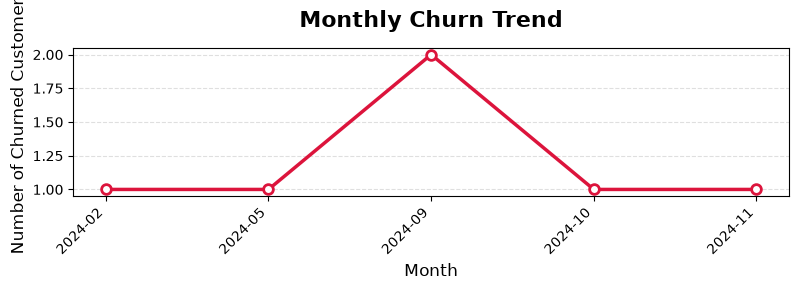

In [99]:
# 4.1 Monthly Churn Trend (Time Series KPI)

# Keep only churned customers
churned_df = df_visual.dropna(subset=['cancellation_date']).copy()

# Group churned customers by month
monthly_churn = (
    churned_df
    .groupby(churned_df['cancellation_date'].dt.to_period('M'))
    .size()
)
plt.figure(figsize=(8,3))
plt.plot(
    monthly_churn.index.astype(str),
    monthly_churn.values,
    marker='o',
    linewidth=2.5,
    markersize=7,
    color='crimson',
    markerfacecolor='white',
    markeredgewidth=2
)

# Styling
plt.title('Monthly Churn Trend', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Churned Customers', fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

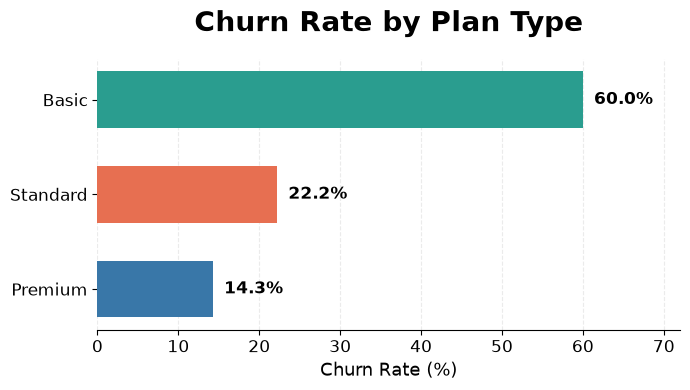

In [100]:
# 4.2 Churn Rate by Plan type

churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean().mul(100)
churn_plan = churn_plan.sort_values()
fig, ax = plt.subplots(figsize=(7,4))
colors = ['#3977A8', '#E76F51', '#2A9D8F', '#E9C46A', '#8E6DB7']
bars = ax.barh(
    churn_plan.index.astype(str),
    churn_plan.values,
    height=0.6,
    color=colors[:len(churn_plan)],
    edgecolor='none'
)
ax.bar_label(
    bars,
    fmt='%.1f%%',
    padding=8,
    fontsize=12,
    fontweight='bold'
)
ax.set_title('Churn Rate by Plan Type', fontsize=20, fontweight='bold', pad=20)
ax.set_xlabel('Churn Rate (%)', fontsize=13)
ax.set_ylabel('')
ax.set_xlim(0, max(churn_plan.max() * 1.2, 1))
ax.tick_params(axis='both', labelsize=12)
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.show()

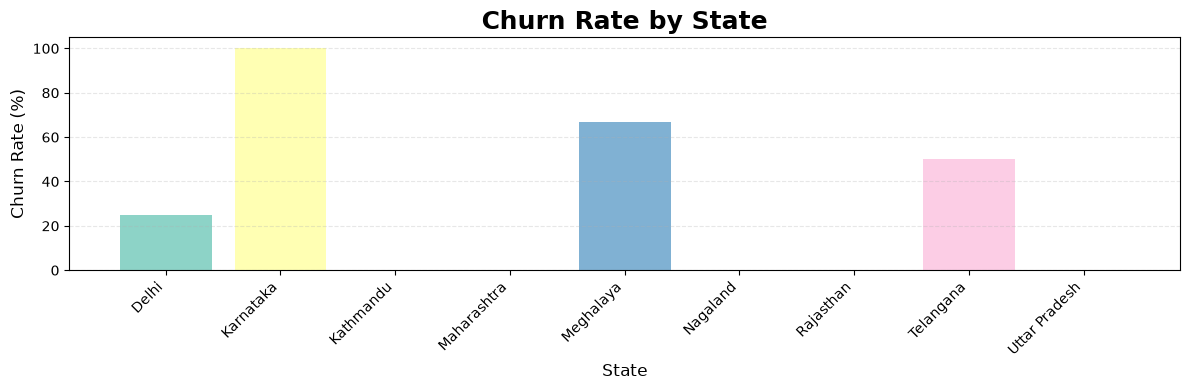

In [109]:
# 4.3 Churn by States

churn_state = df_visual.groupby('state')['churn_flag'].mean().mul(100)


plt.figure(figsize=(12, 4))
plt.bar(
    x=churn_state.index,
    height=churn_state.values,
    color=plt.cm.Set3(range(len(churn_state)))
)

plt.title('Churn Rate by State', fontsize=18, fontweight='bold')
plt.xlabel('State', fontsize=12)
plt.ylabel('Churn Rate (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [110]:
# 5. Visualization using Seaborn


In [131]:
# Heatmap (Correlation Matrix)

df_encoded = df_visual[
    ['plan_type', 'contract_type', 'churn_score',
     'churn_flag', 'churn_risk', 'escalations']
].copy()

# One-Hot Encoding
df_encoded = pd.get_dummies(
    df_encoded,
    columns=['plan_type', 'contract_type'],
    drop_first=True,
    dtype=int
)

# Ordinal Encoding
risk_order = {'Low': 0, 'Medium': 1, 'High': 2}
df_encoded['churn_risk'] = df_encoded['churn_risk'].map(risk_order)

# Encode escalations only if values are Y/N
if df_encoded['escalations'].dtype == 'object':
    df_encoded['escalations'] = df_encoded['escalations'].map({'N': 0, 'Y': 1})

df_encoded['churn_risk'] = df_encoded['churn_risk'].astype(int)

In [132]:
df_encoded

,churn_score,churn_flag,churn_risk,escalations,plan_type_Premium,plan_type_Standard,contract_type_Monthly
0,12,0,0,NaN,0,1,0
1,91,1,2,1.0,1,0,0
2,34,0,0,NaN,0,0,1
3,8,0,0,NaN,1,0,0
4,88,1,2,1.0,0,1,1
5,22,0,0,0.0,0,1,0
6,79,1,2,0.0,0,0,1
7,5,0,0,NaN,1,0,0
8,34,0,0,NaN,0,1,1
9,41,0,0,NaN,0,0,0


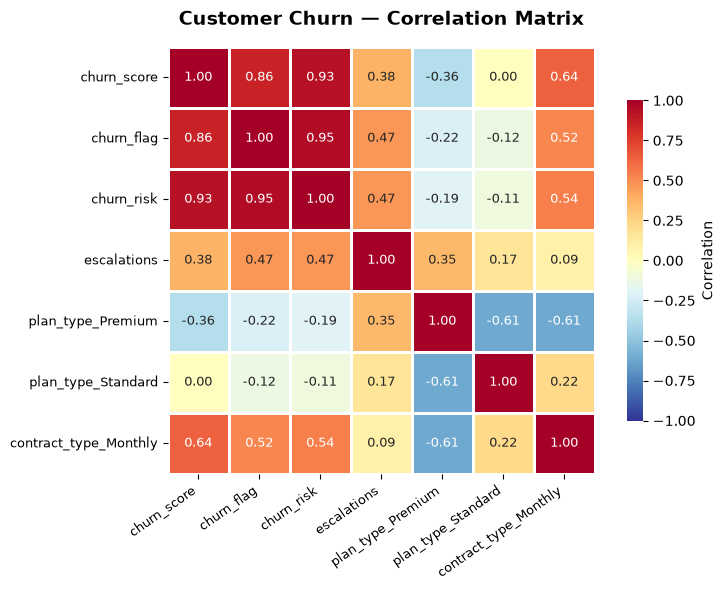

In [133]:
# 5. Correlation Matrix and Beautiful Heatmap

corr_matrix = df_encoded.corr(numeric_only=True)

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdYlBu_r',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=1,
    linecolor='white',
    square=True,
    annot_kws={'size': 9},
    cbar_kws={'shrink': 0.75, 'label': 'Correlation'}
)

plt.title(
    'Customer Churn — Correlation Matrix',
    fontsize=14,
    fontweight='bold',
    pad=16
)

plt.xticks(rotation=35, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

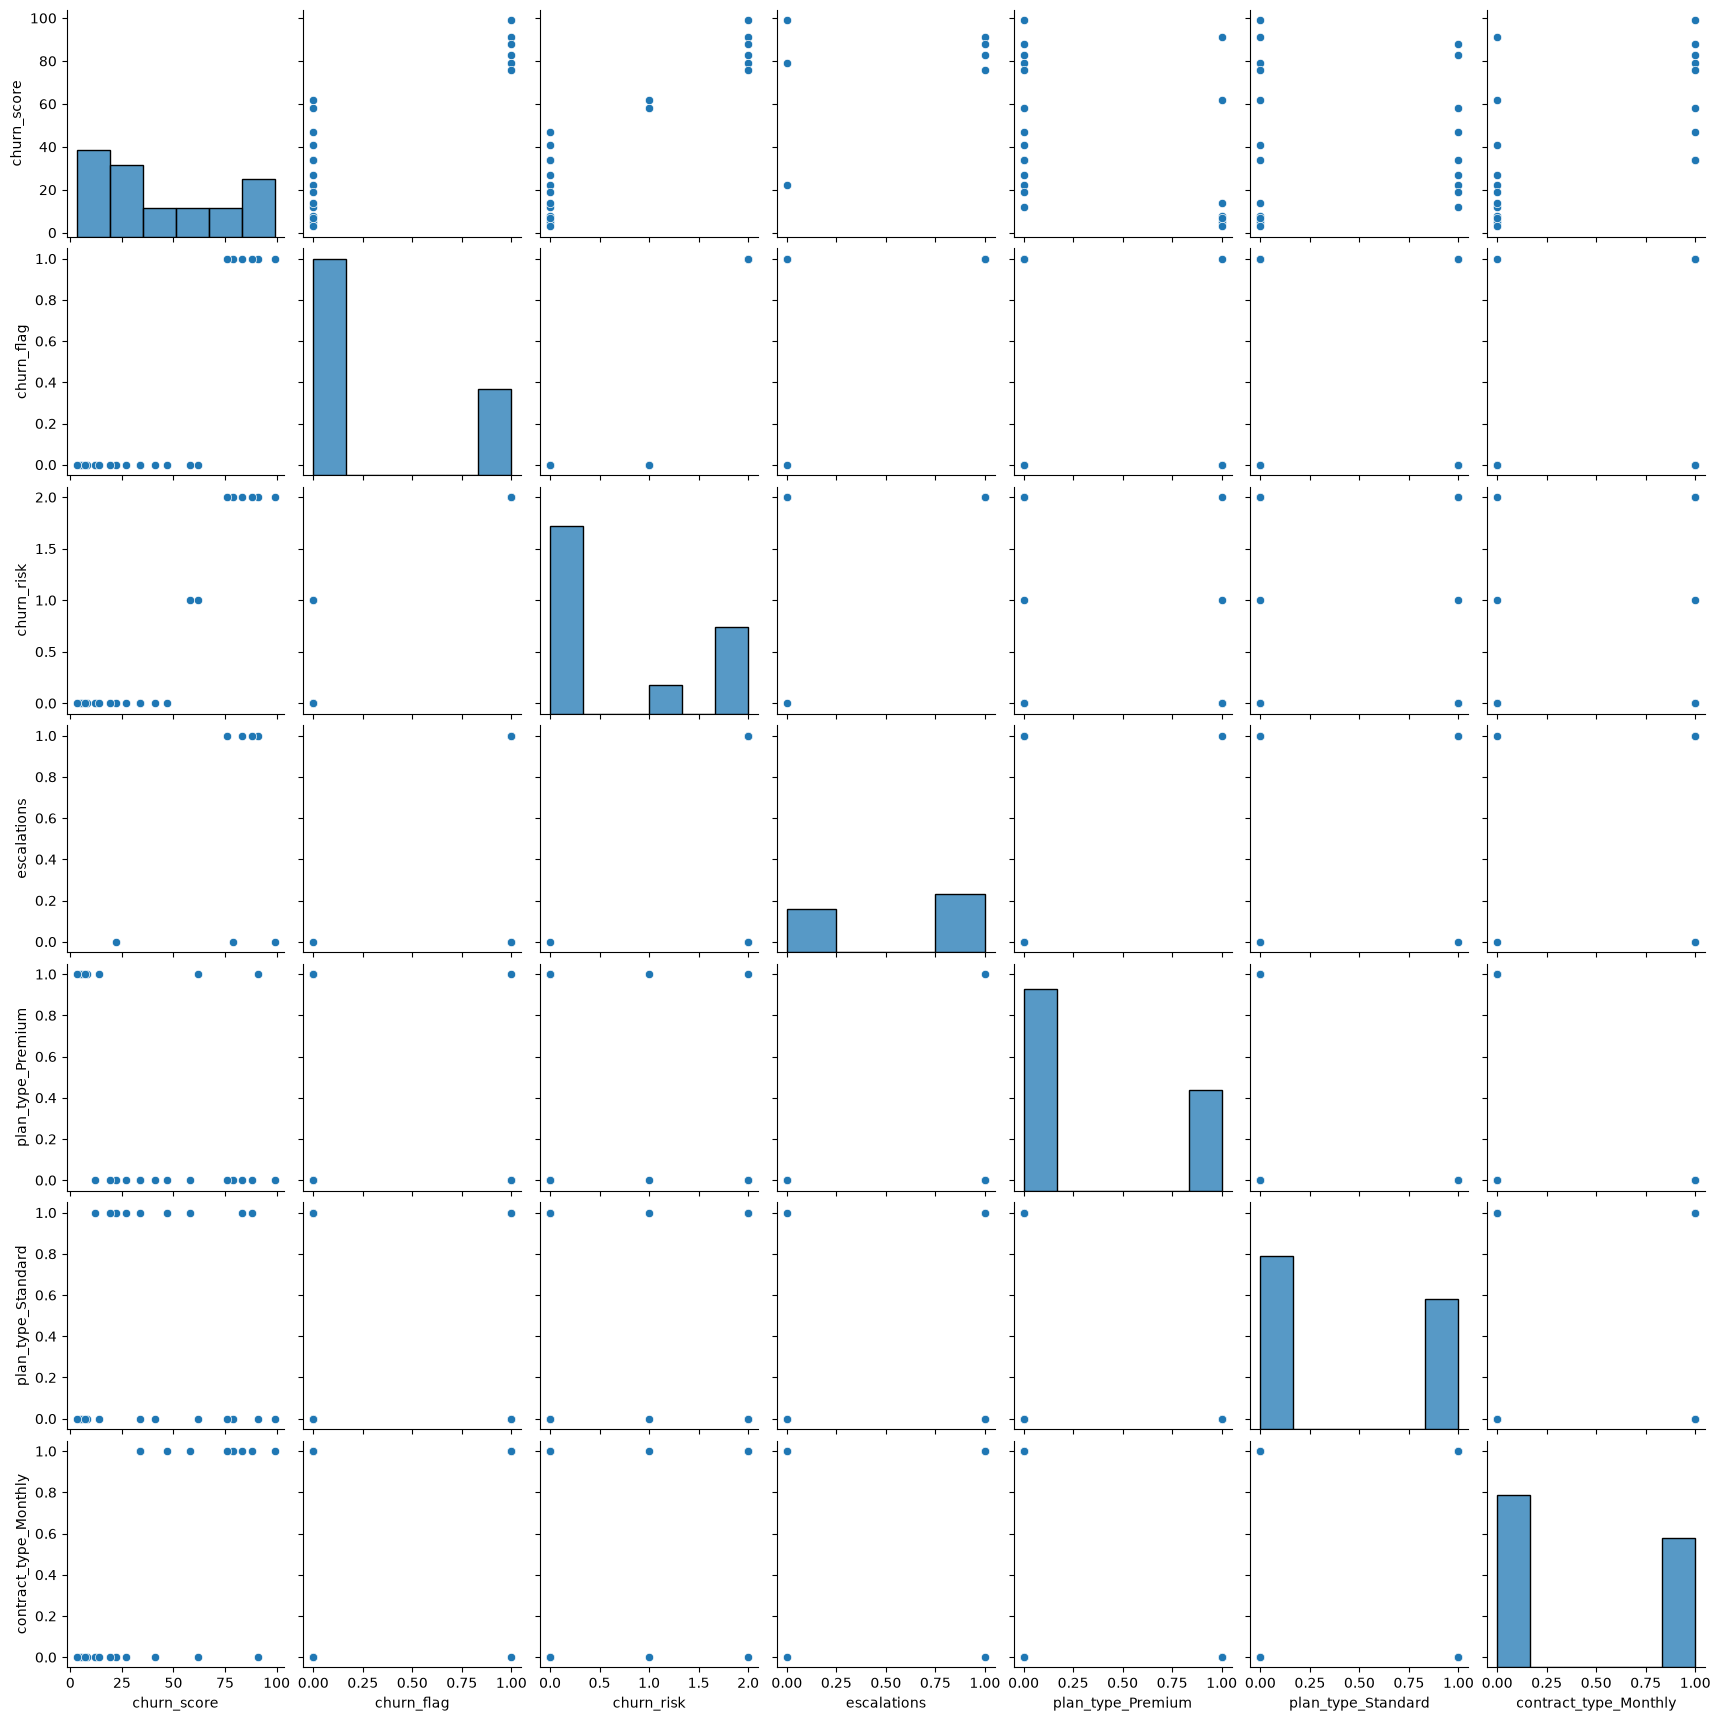

In [135]:
# pairplot - Plot pairwise relationships in a dataset
sns.pairplot(df_encoded)

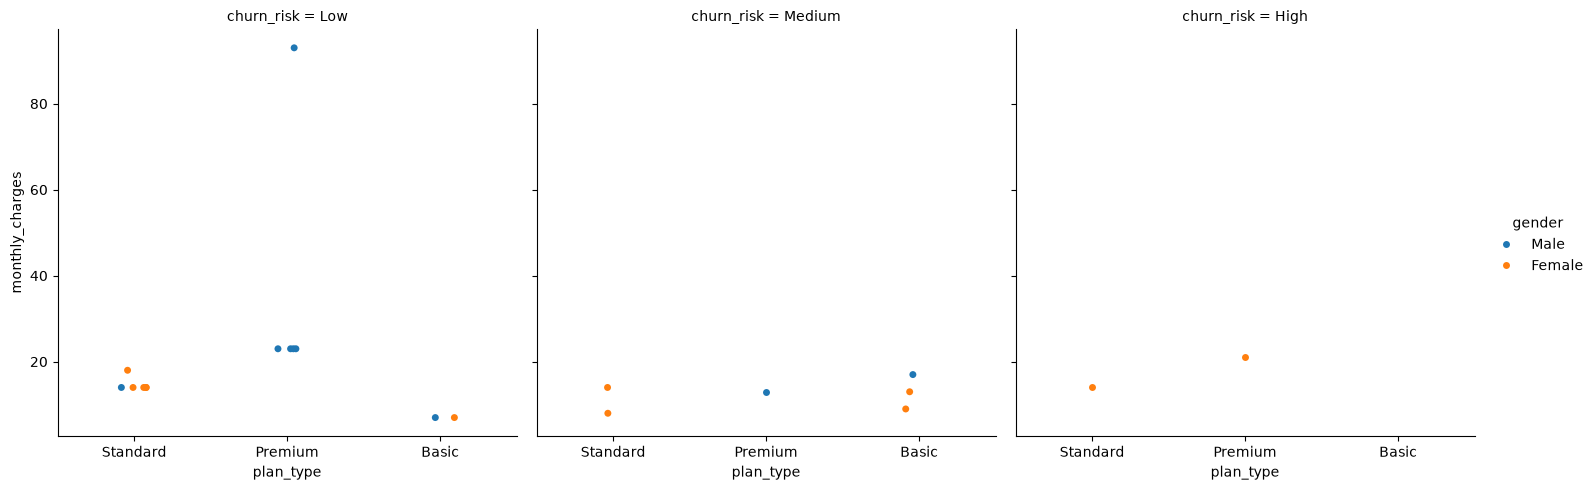

In [136]:
# catplt/Facegrid plot - multi-dim comparison

sns.catplot(data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk')

In [138]:
# Pivot Table



In [139]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc = 'mean'
)

,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [142]:
# pivot table using multiple cols and agg type

pd.pivot_table(
    data=df_visual,
    values=['churn_flag', 'customerid', 'monthly_charges'],
    index='plan_type',
    aggfunc={
        'churn_flag': 'mean',
        'customerid': 'nunique',
        'monthly_charges': 'sum'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


In [143]:
# Data-Analysis  Completed Here:)